In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

# Set display options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define data path

DATA_PATH = "../data/processed/"

# Load cleaned datasets

customers = pd.read_csv(DATA_PATH + "customers_cleaned.csv")
orders = pd.read_csv(DATA_PATH + "orders_cleaned.csv")
order_items = pd.read_csv(DATA_PATH + "order_items_cleaned.csv")
payments = pd.read_csv(DATA_PATH + "payments_cleaned.csv")
reviews = pd.read_csv(DATA_PATH + "reviews_cleaned.csv")
products = pd.read_csv(DATA_PATH + "products_cleaned.csv")
sellers = pd.read_csv(DATA_PATH + "sellers_cleaned.csv")
geolocation = pd.read_csv(DATA_PATH + "geolocation_cleaned.csv")
category_translation = pd.read_csv(DATA_PATH + "category_translation_cleaned.csv")

print("All cleaned datasets loaded successfully!")

All cleaned datasets loaded successfully!


In [3]:
# Check dataset dimensions

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Geolocation": geolocation,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

Customers: 99,441 rows, 5 columns
Orders: 99,441 rows, 8 columns
Order Items: 112,650 rows, 7 columns
Payments: 103,886 rows, 5 columns
Reviews: 99,224 rows, 7 columns
Products: 32,951 rows, 9 columns
Sellers: 3,095 rows, 4 columns
Geolocation: 738,332 rows, 5 columns
Category Translation: 71 rows, 2 columns


In [5]:
orders["order_purchase_timestamp"].dtype

<StringDtype(storage='python', na_value=nan)>

In [6]:
# Convert date columns to datetime

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

# Verify data types
orders[date_columns].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [7]:
# Sales Performance Metrics

total_orders = orders["order_id"].nunique()

total_items_sold = order_items["order_item_id"].count()

total_revenue = order_items["price"].sum()

print(f"Total Orders       : {total_orders:,}")
print(f"Total Items Sold   : {total_items_sold:,}")
print(f"Total Revenue      : R$ {total_revenue:,.2f}")

Total Orders       : 99,441
Total Items Sold   : 112,650
Total Revenue      : R$ 13,591,643.70


In [8]:
# Calculate Average Order Value (AOV)

aov = total_revenue / total_orders

print(f"Average Order Value (AOV): R$ {aov:,.2f}")

Average Order Value (AOV): R$ 136.68


In [9]:
# Extract year-month from purchase timestamp

order_items_analysis = order_items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

order_items_analysis["order_month"] = (
    order_items_analysis["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate monthly revenue

monthly_revenue = (
    order_items_analysis
    .groupby("order_month")["price"]
    .sum()
    .reset_index()
)

monthly_revenue["order_month"] = monthly_revenue["order_month"].astype(str)

monthly_revenue.columns = ["Month", "Revenue"]

monthly_revenue.head()

,Month,Revenue
0,2016-09,267.36
1,2016-10,"49,507.66"
2,2016-12,10.90
3,2017-01,"120,312.87"
4,2017-02,"247,303.02"


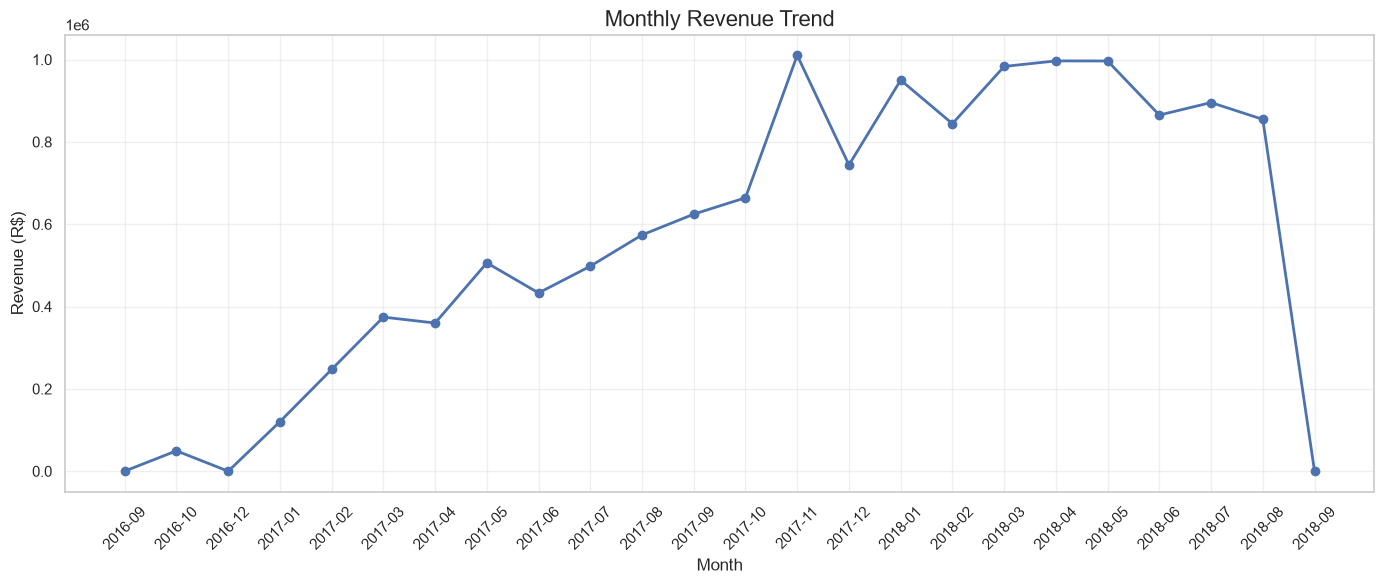

In [10]:
# Visualize Monthly Revenue Trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue["Month"],
    monthly_revenue["Revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# Check the last 6 months of revenue

monthly_revenue.tail(6)

,Month,Revenue
18,2018-04,"996,647.75"
19,2018-05,"996,517.68"
20,2018-06,"865,124.31"
21,2018-07,"895,507.22"
22,2018-08,"854,686.33"
23,2018-09,145.00


In [12]:
# Check the latest purchase date

orders["order_purchase_timestamp"].max()

Timestamp('2018-10-17 17:30:18')

In [13]:
# Calculate monthly order count

orders["order_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

monthly_orders = (
    orders.groupby("order_month")["order_id"]
    .nunique()
    .reset_index()
)

monthly_orders["order_month"] = monthly_orders["order_month"].astype(str)

monthly_orders.columns = ["Month", "Total Orders"]

monthly_orders.tail(6)

,Month,Total Orders
19,2018-05,6873
20,2018-06,6167
21,2018-07,6292
22,2018-08,6512
23,2018-09,16
24,2018-10,4


In [14]:
# Filter monthly revenue until August 2018

monthly_revenue_complete = monthly_revenue[
    monthly_revenue["Month"] <= "2018-08"
].copy()

# Display the latest months
monthly_revenue_complete.tail()

,Month,Revenue
18,2018-04,"996,647.75"
19,2018-05,"996,517.68"
20,2018-06,"865,124.31"
21,2018-07,"895,507.22"
22,2018-08,"854,686.33"


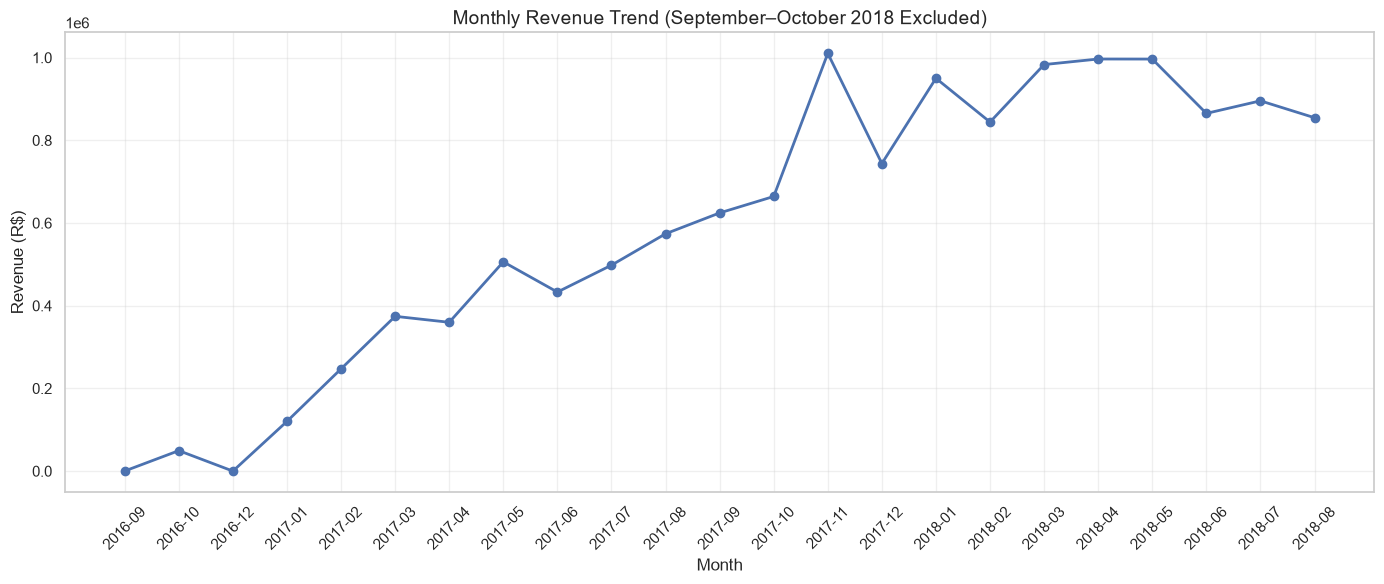

In [15]:
# Visualize Monthly Revenue Trend (Complete Period)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue_complete["Month"],
    monthly_revenue_complete["Revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend (September–October 2018 Excluded)", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

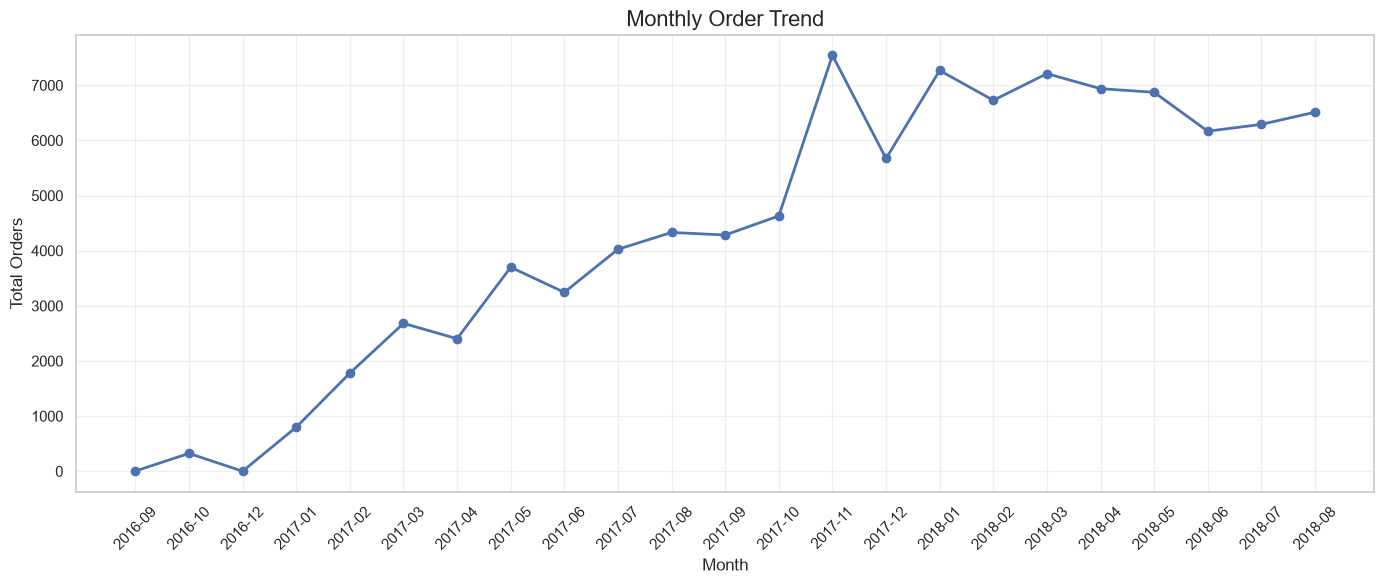

In [16]:
# Filter monthly orders until August 2018

monthly_orders_complete = monthly_orders[
    monthly_orders["Month"] <= "2018-08"
].copy()

# Visualize Monthly Order Trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_orders_complete["Month"],
    monthly_orders_complete["Total Orders"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Order Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Orders")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
# Merge order items with products

product_sales = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Merge with category translation

product_sales = product_sales.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# Handle missing category names

product_sales["product_category_name_english"] = (
    product_sales["product_category_name_english"]
    .fillna("Unknown")
)

print("Product sales dataset created successfully!")
print("Shape:", product_sales.shape)

product_sales.head()

Product sales dataset created successfully!
Shape: (112650, 9)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools


In [18]:
# Check missing values in product_sales

product_sales[
    ["price", "freight_value", "product_category_name"]
].isnull().sum()

price                       0
freight_value               0
product_category_name    1603
dtype: int64

In [19]:
# Calculate revenue by product category

category_revenue = (
    product_sales
    .groupby("product_category_name_english")["price"]
    .sum()
    .reset_index()
    .sort_values(by="price", ascending=False)
)

category_revenue.columns = ["Product Category", "Revenue"]

category_revenue.head(10)

,Product Category,Revenue
44,health_beauty,"1,258,681.34"
71,watches_gifts,"1,205,005.68"
8,bed_bath_table,"1,036,988.68"
66,sports_leisure,"988,048.97"
16,computers_accessories,"911,954.32"
40,furniture_decor,"729,762.49"
21,cool_stuff,"635,290.85"
50,housewares,"632,248.66"
6,auto,"592,720.11"
43,garden_tools,"485,256.46"


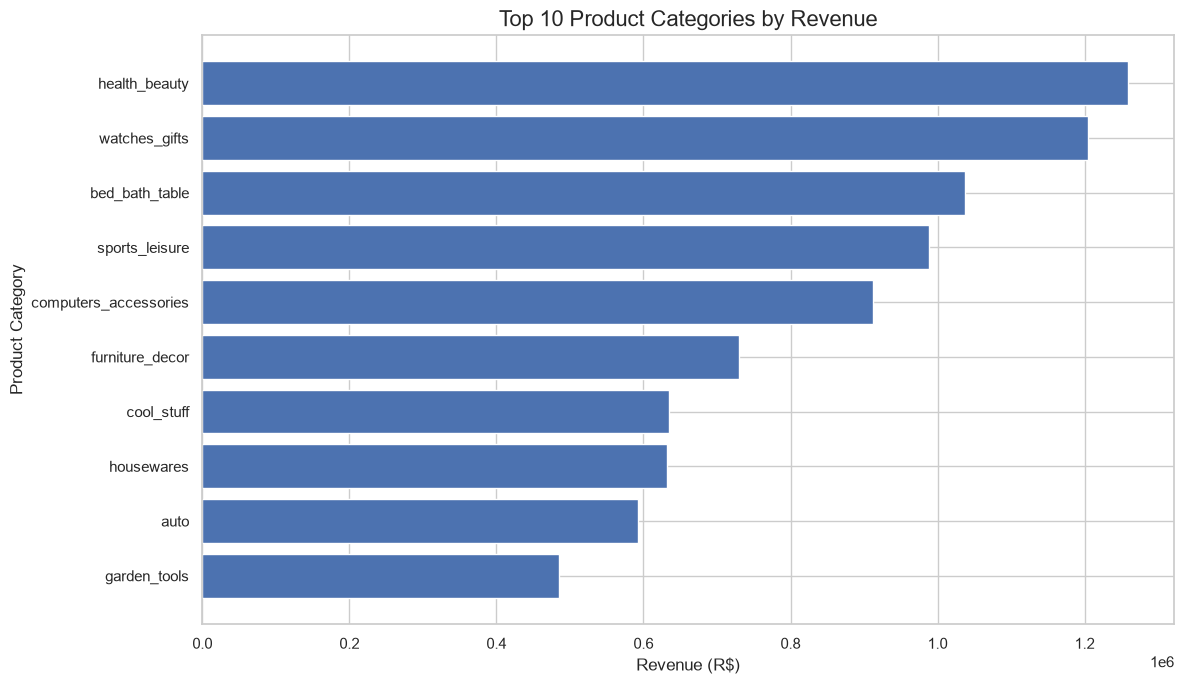

In [20]:
# Visualize Top 10 Product Categories by Revenue

top_10_categories = category_revenue.head(10).sort_values(
    by="Revenue",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_categories["Product Category"],
    top_10_categories["Revenue"]
)

plt.title("Top 10 Product Categories by Revenue", fontsize=16)
plt.xlabel("Revenue (R$)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [21]:
# Calculate items sold by product category

category_items = (
    product_sales
    .groupby("product_category_name_english")["order_item_id"]
    .count()
    .reset_index()
    .sort_values(by="order_item_id", ascending=False)
)

category_items.columns = ["Product Category", "Items Sold"]

category_items.head(10)

,Product Category,Items Sold
8,bed_bath_table,11115
44,health_beauty,9670
66,sports_leisure,8641
40,furniture_decor,8334
16,computers_accessories,7827
50,housewares,6964
71,watches_gifts,5991
69,telephony,4545
43,garden_tools,4347
6,auto,4235


In [22]:
# Calculate average selling price by category

category_avg_price = (
    product_sales
    .groupby("product_category_name_english")["price"]
    .mean()
    .reset_index()
    .sort_values(by="price", ascending=False)
)

category_avg_price.columns = [
    "Product Category",
    "Average Selling Price"
]

category_avg_price.head(10)

,Product Category,Average Selling Price
15,computers,"1,098.34"
65,small_appliances_home_oven_and_coffee,624.29
46,home_appliances_2,476.12
1,agro_industry_and_commerce,342.12
57,musical_instruments,281.62
64,small_appliances,280.78
35,fixed_telephony,225.69
20,construction_tools_safety,208.99
71,watches_gifts,201.14
2,air_conditioning,185.27


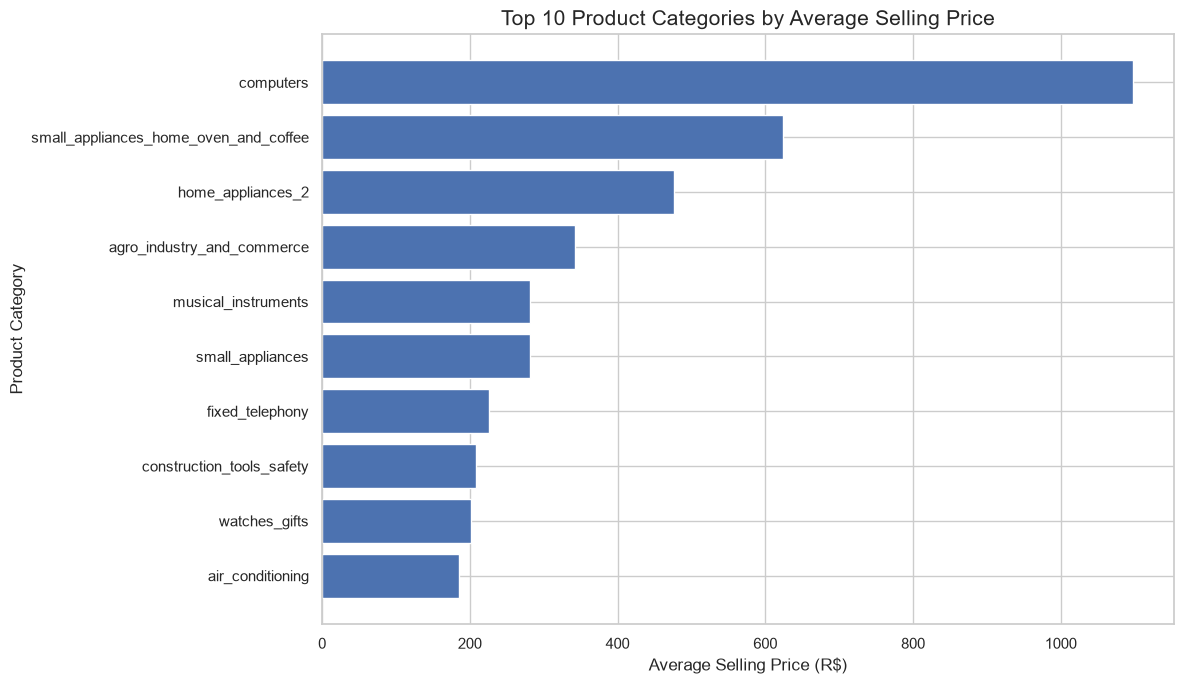

In [23]:
# Visualize Top 10 Categories by Average Selling Price

top_10_avg_price = category_avg_price.head(10).sort_values(
    by="Average Selling Price",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_avg_price["Product Category"],
    top_10_avg_price["Average Selling Price"]
)

plt.title("Top 10 Product Categories by Average Selling Price", fontsize=15)
plt.xlabel("Average Selling Price (R$)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [24]:
# Calculate total unique customers

total_customers = customers["customer_unique_id"].nunique()

print(f"Total Unique Customers: {total_customers:,}")

Total Unique Customers: 96,096


In [25]:
# Calculate customers by state

customers_by_state = (
    customers
    .groupby("customer_state")["customer_unique_id"]
    .nunique()
    .reset_index()
    .sort_values(by="customer_unique_id", ascending=False)
)

customers_by_state.columns = ["State", "Total Customers"]

customers_by_state.head(10)

,State,Total Customers
25,SP,40302
18,RJ,12384
10,MG,11259
22,RS,5277
17,PR,4882
23,SC,3534
4,BA,3277
6,DF,2075
7,ES,1964
8,GO,1952


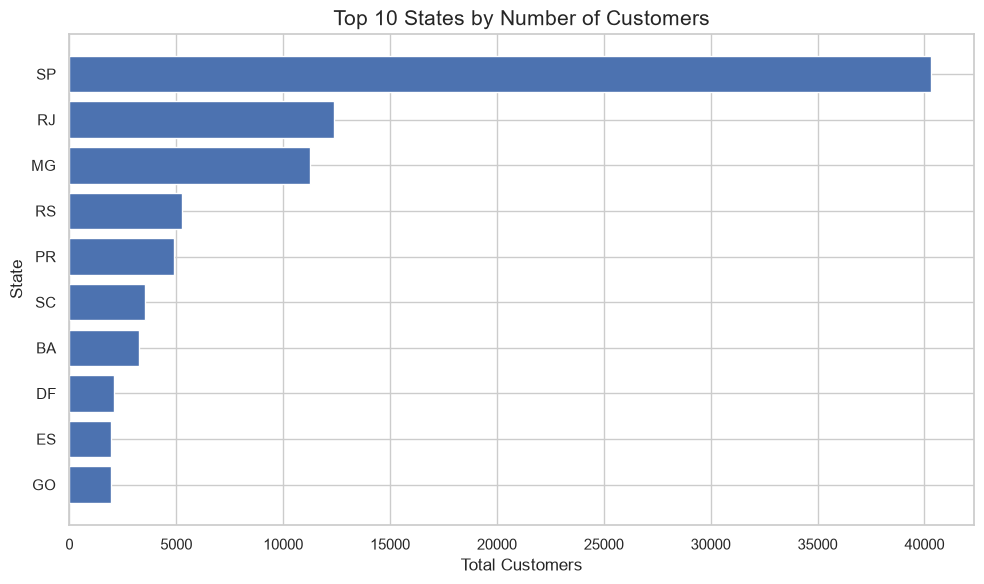

In [26]:
# Visualize Top 10 States by Customer Count

top_10_states = customers_by_state.head(10).sort_values(
    by="Total Customers",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_states["State"],
    top_10_states["Total Customers"]
)

plt.title("Top 10 States by Number of Customers", fontsize=15)
plt.xlabel("Total Customers")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [27]:
# Count orders per unique customer

customer_orders = (
    orders.merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left"
    )
    .groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index()
)

customer_orders.columns = ["Customer ID", "Total Orders"]

# Classify customer purchase frequency

repeat_customers = customer_orders[
    customer_orders["Total Orders"] > 1
]

one_time_customers = customer_orders[
    customer_orders["Total Orders"] == 1
]

print(f"One-time Customers : {len(one_time_customers):,}")
print(f"Repeat Customers   : {len(repeat_customers):,}")
print(f"Total Customers    : {len(customer_orders):,}")

One-time Customers : 93,099
Repeat Customers   : 2,997
Total Customers    : 96,096


In [28]:
# Calculate repeat purchase rate

repeat_purchase_rate = (
    len(repeat_customers) / len(customer_orders)
) * 100

one_time_rate = (
    len(one_time_customers) / len(customer_orders)
) * 100

print(f"Repeat Purchase Rate : {repeat_purchase_rate:.2f}%")
print(f"One-time Purchase Rate: {one_time_rate:.2f}%")

Repeat Purchase Rate : 3.12%
One-time Purchase Rate: 96.88%


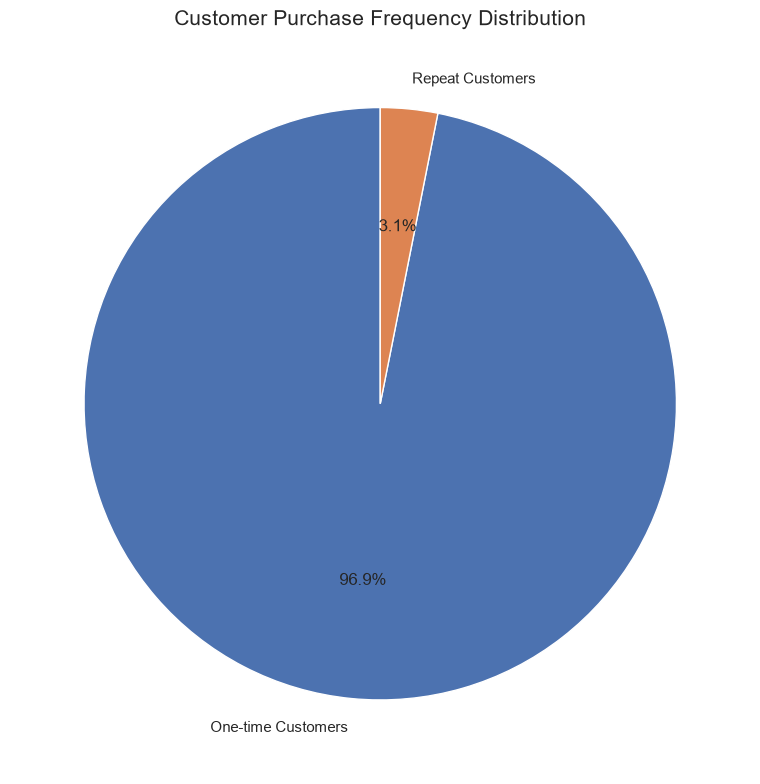

In [29]:
# Prepare customer purchase frequency data

customer_frequency = pd.DataFrame({
    "Customer Type": ["One-time Customers", "Repeat Customers"],
    "Total Customers": [
        len(one_time_customers),
        len(repeat_customers)
    ]
})

# Visualize customer purchase frequency

plt.figure(figsize=(8, 8))

plt.pie(
    customer_frequency["Total Customers"],
    labels=customer_frequency["Customer Type"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Purchase Frequency Distribution", fontsize=15)
plt.tight_layout()
plt.show()

In [32]:
# Calculate total unique sellers

total_sellers = sellers["seller_id"].nunique()

print(f"Total Unique Sellers: {total_sellers:,}")

Total Unique Sellers: 3,095


In [33]:
# Merge order items with seller data

seller_sales = order_items.merge(
    sellers[["seller_id", "seller_state"]],
    on="seller_id",
    how="left"
)

# Calculate revenue by seller

seller_revenue = (
    seller_sales
    .groupby("seller_id")["price"]
    .sum()
    .reset_index()
    .sort_values(by="price", ascending=False)
)

seller_revenue.columns = ["Seller ID", "Revenue"]

# Display Top 10 Sellers

seller_revenue.head(10)

,Seller ID,Revenue
857,4869f7a5dfa277a7dca6462dcf3b52b2,"229,472.63"
1013,53243585a1d6dc2643021fd1853d8905,"222,776.05"
881,4a3ca9315b744ce9f8e9374361493884,"200,472.92"
3024,fa1c13f2614d7b5c4749cbc52fecda94,"194,042.03"
1535,7c67e1448b00f6e969d365cea6b010ab,"187,923.89"
1560,7e93a43ef30c4f03f38b393420bc753a,"176,431.87"
2643,da8622b14eb17ae2831f4ac5b9dab84a,"160,236.57"
1505,7a67c85e85bb2ce8582c35f2203ad736,"141,745.53"
192,1025f0e2d44d7041d6cf58b6550e0bfa,"138,968.55"
1824,955fee9216a65b617aa5c0531780ce60,"135,171.70"


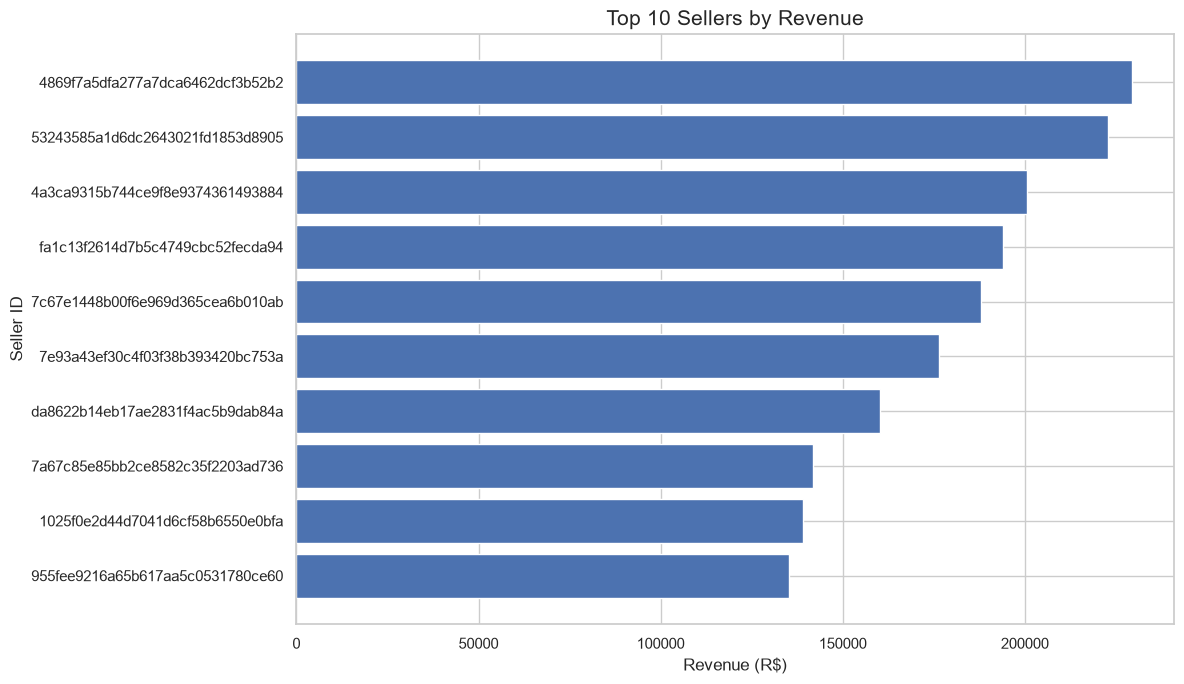

In [34]:
# Prepare Top 10 Sellers

top_10_sellers = seller_revenue.head(10).sort_values(
    by="Revenue",
    ascending=True
)

# Visualize Top 10 Sellers by Revenue

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_sellers["Seller ID"],
    top_10_sellers["Revenue"]
)

plt.title("Top 10 Sellers by Revenue", fontsize=15)
plt.xlabel("Revenue (R$)")
plt.ylabel("Seller ID")

plt.tight_layout()
plt.show()

In [35]:
# Calculate total items sold by each seller

seller_items = (
    order_items
    .groupby("seller_id")["order_item_id"]
    .count()
    .reset_index()
    .sort_values(by="order_item_id", ascending=False)
)

seller_items.columns = ["Seller ID", "Items Sold"]

# Display Top 10 Sellers by Items Sold

seller_items.head(10)

,Seller ID,Items Sold
1235,6560211a19b47992c3666cc44a7e94c0,2033
881,4a3ca9315b744ce9f8e9374361493884,1987
368,1f50f920176fa81dab994f9023523100,1931
2481,cc419e0650a3c5ba77189a1882b7556a,1775
2643,da8622b14eb17ae2831f4ac5b9dab84a,1551
1824,955fee9216a65b617aa5c0531780ce60,1499
192,1025f0e2d44d7041d6cf58b6550e0bfa,1428
1535,7c67e1448b00f6e969d365cea6b010ab,1364
2836,ea8482cd71df3c1969d7b9473ff13abc,1203
1505,7a67c85e85bb2ce8582c35f2203ad736,1171


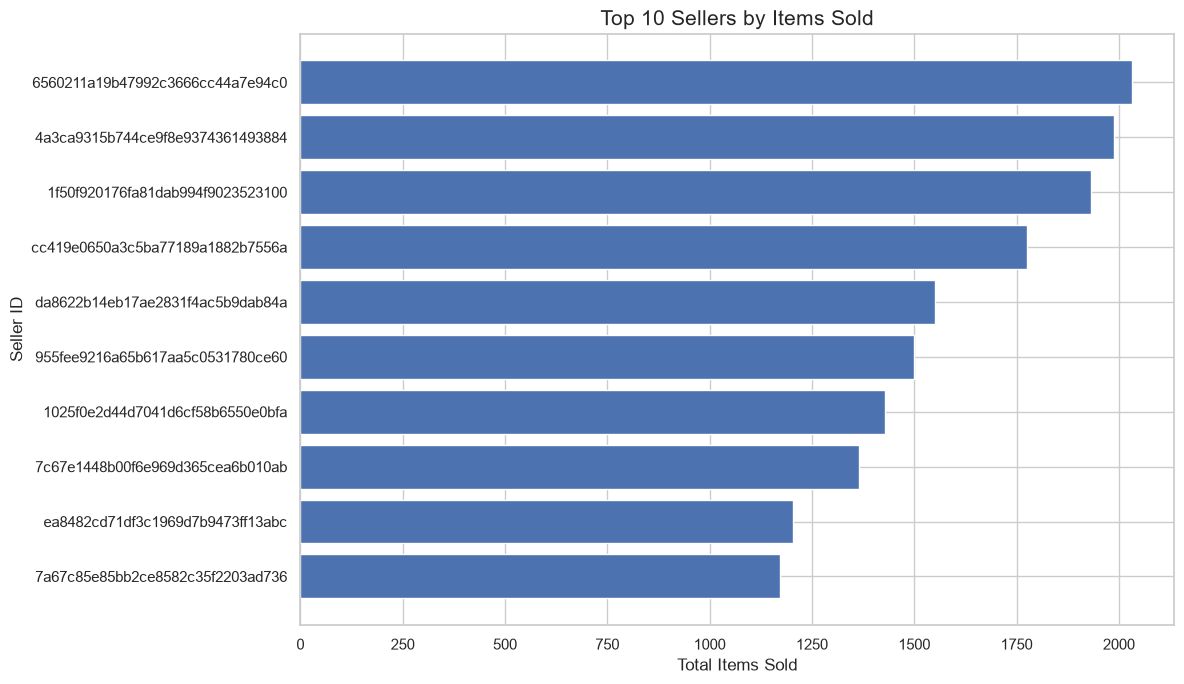

In [36]:
# Prepare Top 10 Sellers

top_10_sellers_items = seller_items.head(10).sort_values(
    by="Items Sold",
    ascending=True
)

# Visualize Top 10 Sellers by Items Sold

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_sellers_items["Seller ID"],
    top_10_sellers_items["Items Sold"]
)

plt.title("Top 10 Sellers by Items Sold", fontsize=15)
plt.xlabel("Total Items Sold")
plt.ylabel("Seller ID")

plt.tight_layout()
plt.show()

In [37]:
# Calculate total sellers by state

sellers_by_state = (
    sellers
    .groupby("seller_state")["seller_id"]
    .nunique()
    .reset_index()
    .sort_values(by="seller_id", ascending=False)
)

sellers_by_state.columns = ["State", "Total Sellers"]

# Display Top 10 States by Number of Sellers

sellers_by_state.head(10)

,State,Total Sellers
22,SP,1849
15,PR,349
8,MG,244
20,SC,190
16,RJ,171
19,RS,129
6,GO,40
4,DF,30
5,ES,23
2,BA,19


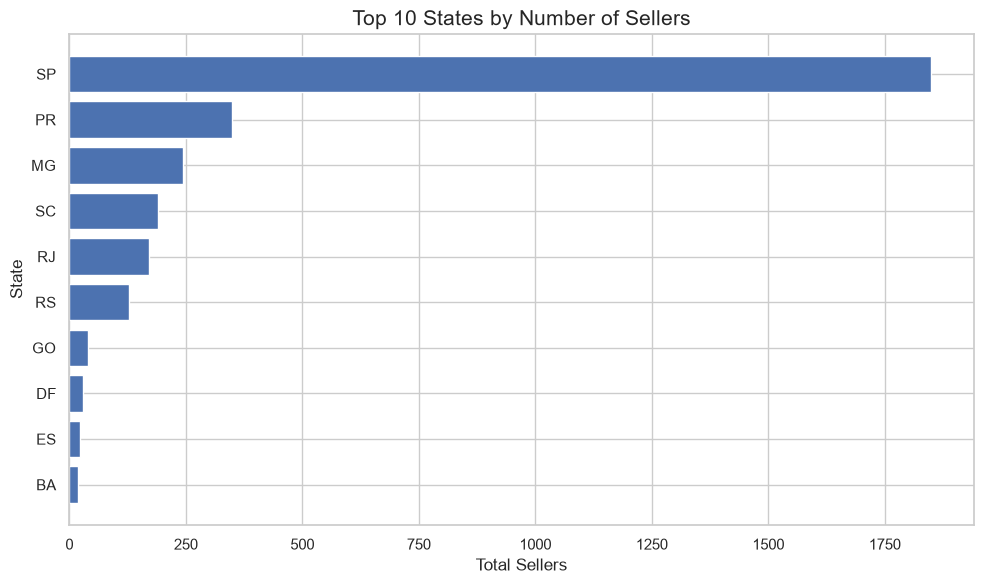

In [38]:
# Prepare Top 10 States by Sellers

top_10_seller_states = sellers_by_state.head(10).sort_values(
    by="Total Sellers",
    ascending=True
)

# Visualize Seller Distribution by State

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_seller_states["State"],
    top_10_seller_states["Total Sellers"]
)

plt.title("Top 10 States by Number of Sellers", fontsize=15)
plt.xlabel("Total Sellers")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [39]:
# Calculate payment method distribution

payment_distribution = (
    payments
    .groupby("payment_type")
    .size()
    .reset_index(name="Total Transactions")
    .sort_values(by="Total Transactions", ascending=False)
)

payment_distribution

,payment_type,Total Transactions
1,credit_card,76795
0,boleto,19784
4,voucher,5775
2,debit_card,1529
3,not_defined,3


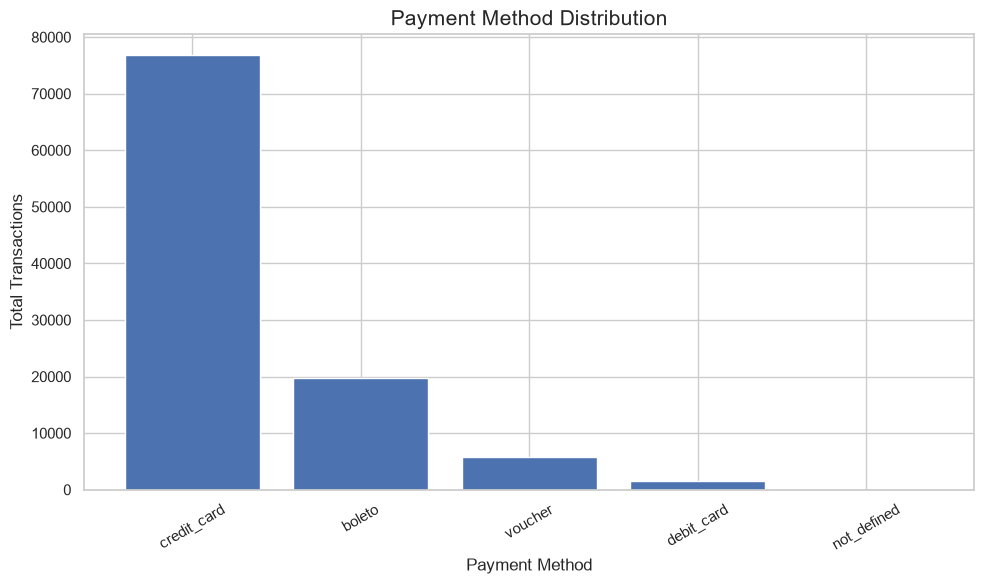

In [40]:
# Visualize Payment Method Distribution

plt.figure(figsize=(10, 6))

plt.bar(
    payment_distribution["payment_type"],
    payment_distribution["Total Transactions"]
)

plt.title("Payment Method Distribution", fontsize=15)
plt.xlabel("Payment Method")
plt.ylabel("Total Transactions")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [41]:
# Calculate total payment value by payment method

payment_value_by_type = (
    payments
    .groupby("payment_type")["payment_value"]
    .sum()
    .reset_index()
    .sort_values(by="payment_value", ascending=False)
)

payment_value_by_type.columns = ["Payment Method", "Total Payment Value"]

payment_value_by_type

,Payment Method,Total Payment Value
1,credit_card,"12,542,084.19"
0,boleto,"2,869,361.27"
4,voucher,"379,436.87"
2,debit_card,"217,989.79"
3,not_defined,0.00


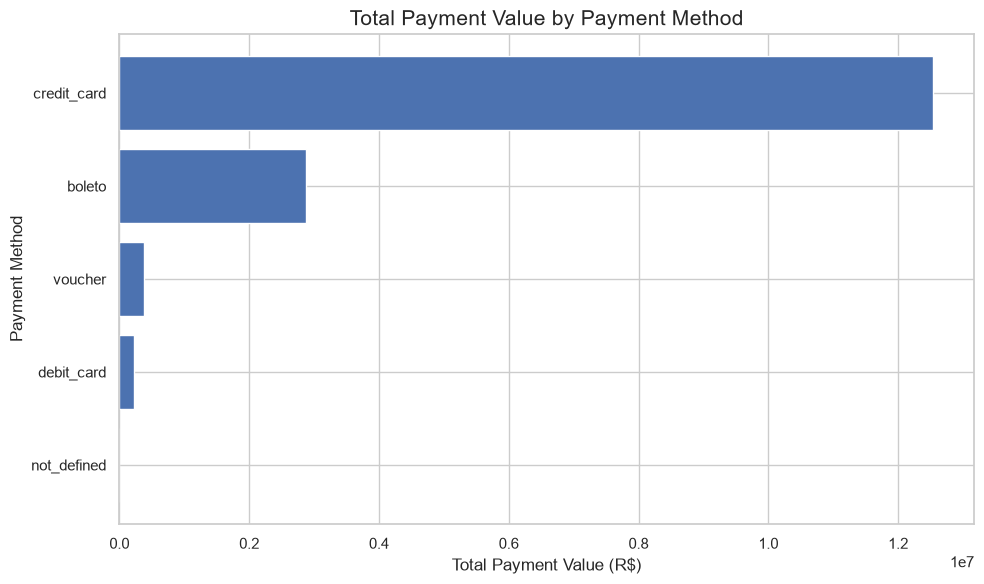

In [42]:
# Prepare payment value data

payment_value_sorted = payment_value_by_type.sort_values(
    by="Total Payment Value",
    ascending=True
)

# Visualize Payment Value by Payment Method

plt.figure(figsize=(10, 6))

plt.barh(
    payment_value_sorted["Payment Method"],
    payment_value_sorted["Total Payment Value"]
)

plt.title("Total Payment Value by Payment Method", fontsize=15)
plt.xlabel("Total Payment Value (R$)")
plt.ylabel("Payment Method")

plt.tight_layout()
plt.show()

In [43]:
# Calculate average payment value by payment method

average_payment_value = (
    payments
    .groupby("payment_type")["payment_value"]
    .mean()
    .reset_index()
    .sort_values(by="payment_value", ascending=False)
)

average_payment_value.columns = ["Payment Method", "Average Payment Value"]

average_payment_value

,Payment Method,Average Payment Value
1,credit_card,163.32
0,boleto,145.03
2,debit_card,142.57
4,voucher,65.70
3,not_defined,0.00


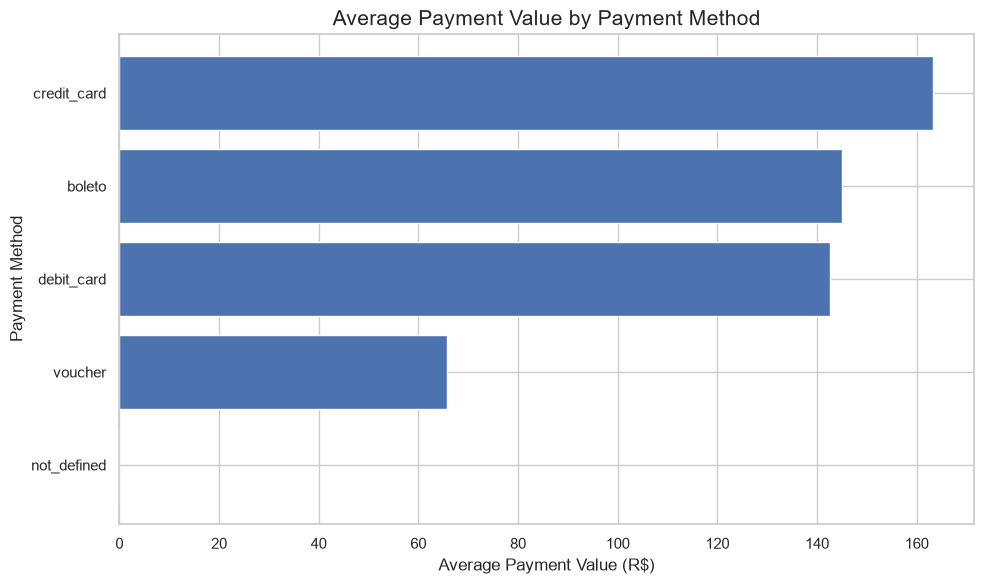

In [44]:
# Prepare average payment value data

average_payment_sorted = average_payment_value.sort_values(
    by="Average Payment Value",
    ascending=True
)

# Visualize Average Payment Value by Payment Method

plt.figure(figsize=(10, 6))

plt.barh(
    average_payment_sorted["Payment Method"],
    average_payment_sorted["Average Payment Value"]
)

plt.title("Average Payment Value by Payment Method", fontsize=15)
plt.xlabel("Average Payment Value (R$)")
plt.ylabel("Payment Method")

plt.tight_layout()
plt.show()

In [45]:
# Filter delivered orders with complete timestamps

delivery_data = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_purchase_timestamp"].notna()) &
    (orders["order_delivered_customer_date"].notna())
].copy()

# Calculate actual delivery time in days

delivery_data["delivery_time_days"] = (
    delivery_data["order_delivered_customer_date"] -
    delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

# Delivery time statistics

delivery_data["delivery_time_days"].describe()

count   96,470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_time_days, dtype: float64

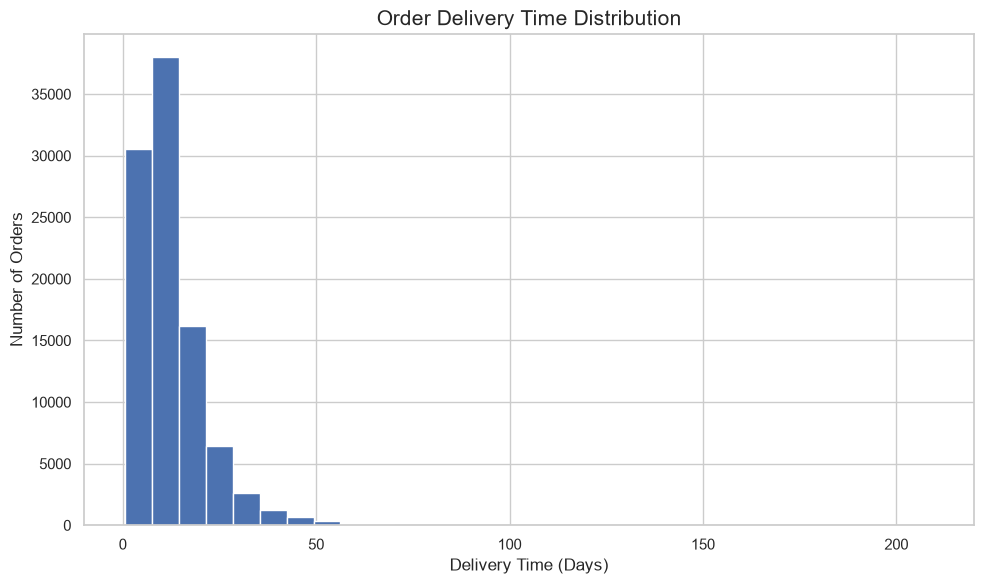

In [46]:
plt.figure(figsize=(10, 6))

plt.hist(
    delivery_data["delivery_time_days"],
    bins=30
)

plt.title("Order Delivery Time Distribution", fontsize=15)
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

In [47]:
# Calculate actual vs estimated delivery

delivery_data["delivery_difference_days"] = (
    delivery_data["order_delivered_customer_date"] -
    delivery_data["order_estimated_delivery_date"]
).dt.total_seconds() / (60 * 60 * 24)

# Classify delivery status

delivery_data["delivery_performance"] = np.where(
    delivery_data["delivery_difference_days"] > 0,
    "Late",
    "On Time or Early"
)

# Display delivery performance distribution

delivery_performance = (
    delivery_data["delivery_performance"]
    .value_counts()
    .reset_index()
)

delivery_performance.columns = ["Delivery Performance", "Total Orders"]

delivery_performance

,Delivery Performance,Total Orders
0,On Time or Early,88644
1,Late,7826


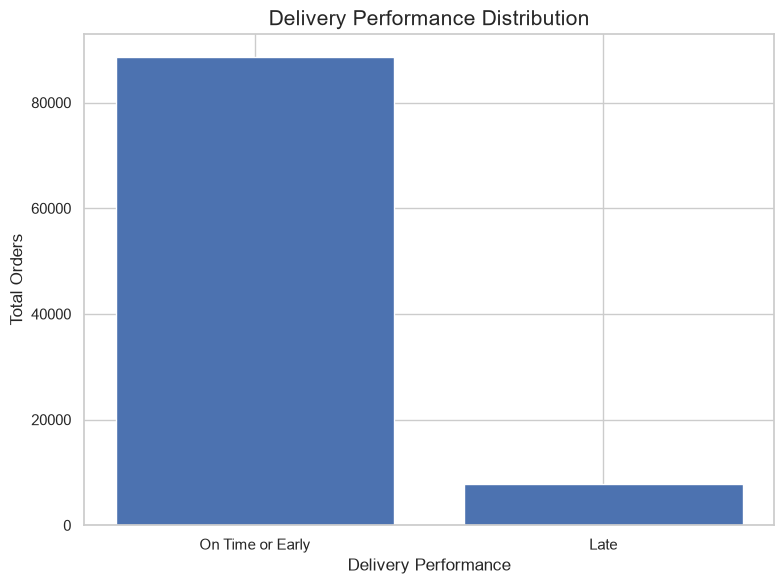

In [48]:
plt.figure(figsize=(8, 6))

plt.bar(
    delivery_performance["Delivery Performance"],
    delivery_performance["Total Orders"]
)

plt.title("Delivery Performance Distribution", fontsize=15)
plt.xlabel("Delivery Performance")
plt.ylabel("Total Orders")

plt.tight_layout()
plt.show()

In [49]:
# Calculate late and on-time orders

late_orders = delivery_data[
    delivery_data["delivery_performance"] == "Late"
]

on_time_orders = delivery_data[
    delivery_data["delivery_performance"] == "On Time or Early"
]

# Calculate delivery rates

late_delivery_rate = (
    len(late_orders) / len(delivery_data)
) * 100

on_time_delivery_rate = (
    len(on_time_orders) / len(delivery_data)
) * 100

print(f"Late Delivery Rate: {late_delivery_rate:.2f}%")
print(f"On-Time or Early Delivery Rate: {on_time_delivery_rate:.2f}%")

Late Delivery Rate: 8.11%
On-Time or Early Delivery Rate: 91.89%


In [50]:
# Calculate review score distribution

review_distribution = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_distribution.columns = ["Review Score", "Total Reviews"]

review_distribution

,Review Score,Total Reviews
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


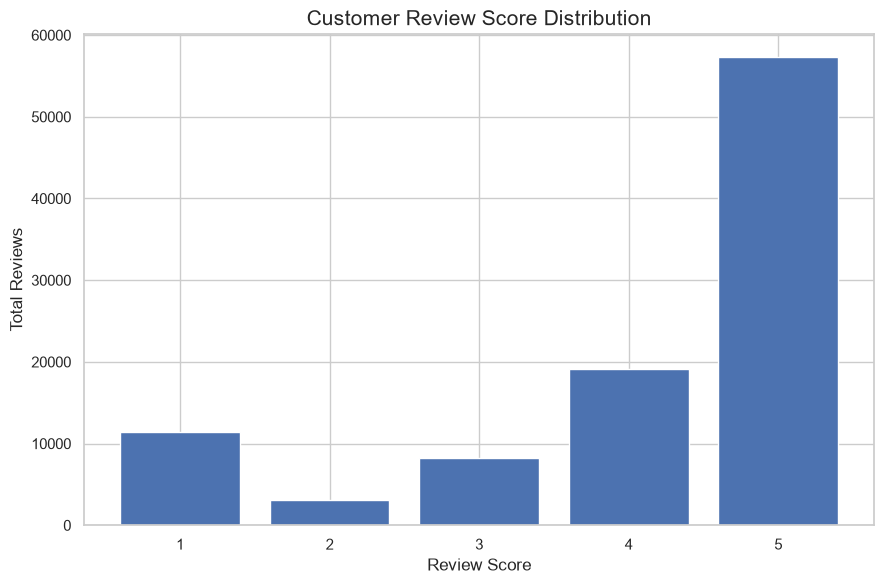

In [51]:
# Visualize Review Score Distribution

plt.figure(figsize=(9, 6))

plt.bar(
    review_distribution["Review Score"],
    review_distribution["Total Reviews"]
)

plt.title("Customer Review Score Distribution", fontsize=15)
plt.xlabel("Review Score")
plt.ylabel("Total Reviews")

plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

In [52]:
# Calculate average review score

average_review_score = reviews["review_score"].mean()

print(f"Average Review Score: {average_review_score:.2f} / 5")

Average Review Score: 4.09 / 5


In [53]:
# Merge delivery data with review data

delivery_review = delivery_data.merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

# Calculate average review score by delivery performance

review_by_delivery = (
    delivery_review
    .groupby("delivery_performance")["review_score"]
    .agg(["mean", "count"])
    .reset_index()
)

review_by_delivery.columns = [
    "Delivery Performance",
    "Average Review Score",
    "Total Reviews"
]

review_by_delivery

,Delivery Performance,Average Review Score,Total Reviews
0,Late,2.57,7700
1,On Time or Early,4.29,88653


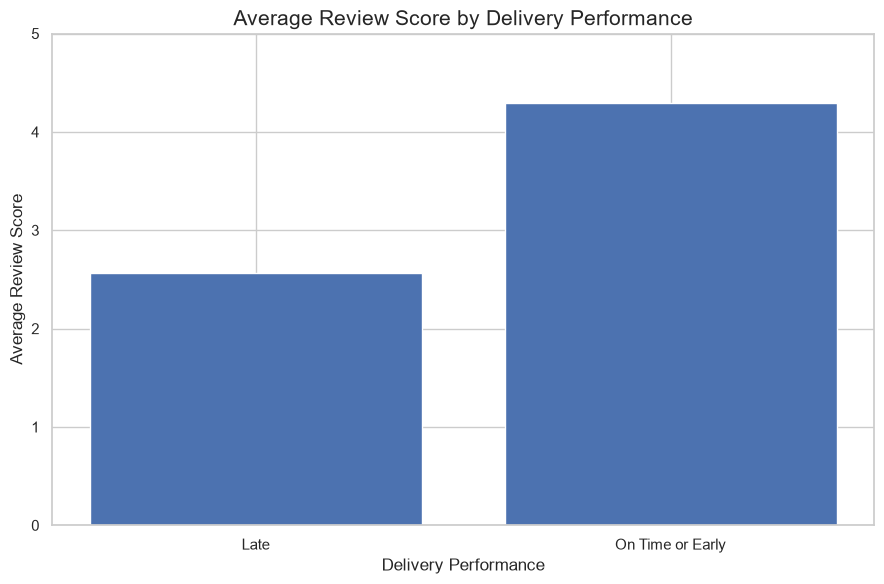

In [54]:
# Visualize Average Review Score by Delivery Performance

plt.figure(figsize=(9, 6))

plt.bar(
    review_by_delivery["Delivery Performance"],
    review_by_delivery["Average Review Score"]
)

plt.title("Average Review Score by Delivery Performance", fontsize=15)
plt.xlabel("Delivery Performance")
plt.ylabel("Average Review Score")

plt.ylim(0, 5)
plt.tight_layout()
plt.show()

In [56]:
# Calculate review score percentage

review_distribution["Percentage"] = (
    review_distribution["Total Reviews"] /
    review_distribution["Total Reviews"].sum()
) * 100

review_distribution

,Review Score,Total Reviews,Percentage
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78


In [57]:
# Create Delivery and Review Summary

delivery_review_summary = pd.DataFrame({
    "Metric": [
        "Total Delivered Orders with Complete Dates",
        "Average Delivery Time (Days)",
        "Median Delivery Time (Days)",
        "Late Delivery Rate (%)",
        "On-Time or Early Delivery Rate (%)",
        "Average Review Score"
    ],
    "Value": [
        len(delivery_data),
        delivery_data["delivery_time_days"].mean(),
        delivery_data["delivery_time_days"].median(),
        late_delivery_rate,
        on_time_delivery_rate,
        average_review_score
    ]
})

delivery_review_summary

,Metric,Value
0,Total Delivered Orders with Complete Dates,"96,470.00"
1,Average Delivery Time (Days),12.56
2,Median Delivery Time (Days),10.22
3,Late Delivery Rate (%),8.11
4,On-Time or Early Delivery Rate (%),91.89
5,Average Review Score,4.09
